<a href="https://colab.research.google.com/github/Rikza-Aidil/simuteh-2330511084/blob/main/B2_citra_warna.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
import os
import sys

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Arahkan direktori kerja aktif ke dalam folder 'notebook' Anda di Drive
os.chdir('/content/drive/MyDrive/Computer Vision/simuteh-2330511084/notebook')

# 3. Masukkan folder 'src' ke dalam sys.path secara mutlak (absolute path)
src_path = '/content/drive/MyDrive/Computer Vision/simuteh-2330511084/src'
if src_path not in sys.path:
    sys.path.append(src_path)

print("Berhasil! Direktori saat ini:", os.getcwd())

Mounted at /content/drive
Berhasil! Direktori saat ini: /content/drive/MyDrive/Computer Vision/simuteh-2330511084/notebook


KB kanal B   : 2.01
KB kanal G   : 1.36
KB kanal R   : 8.63
KB kanal Gray: 4.86
KB kanal H   : 5.78
KB kanal S   : 1.27
KB kanal V   : 2.82


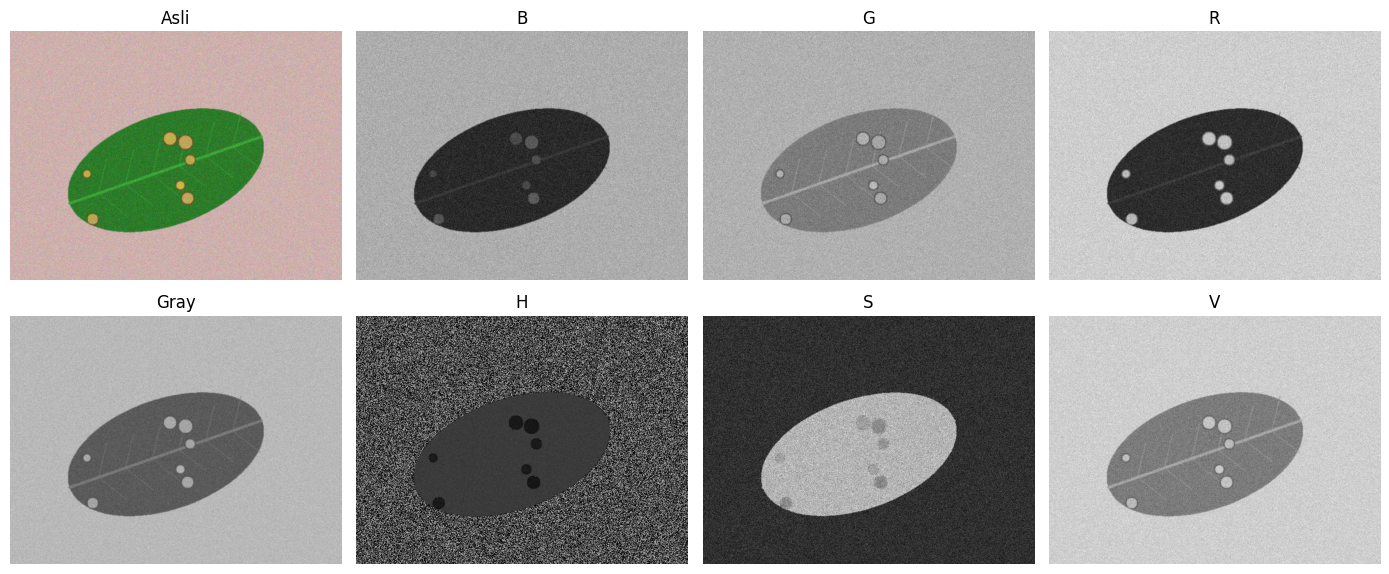

In [2]:
import cv2
import numpy as np
from utils_cv import baca, tampil, kontras_bercak

nama = "teh_041.png"                  # kelas berat, kondisi normal
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)

kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}

# Tampilkan citra asli dan seluruh kanal
tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()), baris=2, ukuran=(14, 6))

# Cetak nilai Kontras Bercak (KB) per kanal
for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

In [3]:
print("--- EKSPERIMEN SAMPLING ---")
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1], interpolation=cv2.INTER_NEAREST)
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md, mb):.2f}")

print("\n--- EKSPERIMEN KUANTISASI ---")
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2**k)
    kuant = (gray // langkah) * langkah
    print(f"k={k}: {len(np.unique(kuant))} level, KB={kontras_bercak(kuant, md, mb):.2f}")

--- EKSPERIMEN SAMPLING ---
fx=0.5: ukuran (240, 320), KB=6.30
fx=0.2: ukuran (96, 128), KB=5.51
fx=0.1: ukuran (48, 64), KB=3.86
fx=0.05: ukuran (24, 32), KB=1.58

--- EKSPERIMEN KUANTISASI ---
k=1: 2 level, KB=7.87
k=2: 4 level, KB=7.68
k=3: 6 level, KB=3.41
k=4: 11 level, KB=4.46
k=8: 166 level, KB=4.86


In [4]:
import pandas as pd

def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img)
    h, s, v = cv2.split(hsv)
    return {
        "B": b, "G": g, "R": r,
        "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
        "H": h, "S": s, "V": v
    }

label = pd.read_csv("../data/sintetis/label.csv")
baris = []

for _, d in label[label.kelas == "berat"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)

    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)

tabel_kb = pd.DataFrame(baris).groupby("kondisi").mean().round(2)
print(tabel_kb)
tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")
print("\nTabel rerata KB berhasil disimpan ke '../hasil/b2_kb_kanal.csv'!")

                   B     G      R  Gray     H     S     V
kondisi                                                  
bayangan        1.39  0.13   5.94  1.41  6.41  1.45  0.61
gelap           1.92  2.21  12.37  5.79  6.68  1.16  4.27
kontras_rendah  0.95  0.79   4.47  2.76  2.29  0.28  1.73
normal          2.05  0.97   8.88  4.41  6.60  1.28  2.33
terang          1.37  0.18   6.54  3.07  5.35  0.72  1.36

Tabel rerata KB berhasil disimpan ke '../hasil/b2_kb_kanal.csv'!


In [5]:
# Uji visual kanal terbaik pada teh_021 (ringan, normal) dan teh_045 (berat, bayangan)
for sample_nama in ["teh_021.png", "teh_045.png"]:
    im_s = baca(f"../data/sintetis/citra/{sample_nama}")
    md_s = cv2.imread(f"../data/sintetis/mask_daun/{sample_nama}", 0)
    mb_s = cv2.imread(f"../data/sintetis/mask_bercak/{sample_nama}", 0)

    # Ambil kanal R (indeks 2 dari BGR) yang umumnya optimal
    kanal_r = im_s[:, :, 2]
    kb_val = kontras_bercak(kanal_r, md_s, mb_s)
    print(f"File: {sample_nama} | KB pada Kanal R = {kb_val:.2f}")

File: teh_021.png | KB pada Kanal R = 8.31
File: teh_045.png | KB pada Kanal R = 6.25
